In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
import os
base = '/content/drive/MyDrive/Custom_OCR'
for folder in ['datasets', 'models', 'results']:
    os.makedirs(f'{base}/{folder}', exist_ok=True)
print(os.listdir(base))

['datasets', 'models', 'results']


In [3]:
!apt-get install -y tesseract-ocr
!pip install pytesseract opencv-python

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (5.3.4-1build5).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.


In [4]:
import cv2, pytesseract, torch
print("OpenCV:", cv2.__version__)
print("Tesseract:", pytesseract.get_tesseract_version())
print("GPU available:", torch.cuda.is_available())

OpenCV: 4.14.0
Tesseract: 5.3.4
GPU available: True


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!ls /content/drive/MyDrive/Custom_OCR/datasets/

 images_raw  'project 1.v1i.darknet.zip'


In [3]:
!unzip -q "/content/drive/MyDrive/Custom_OCR/datasets/project 1.v1i.darknet.zip" -d "/content/drive/MyDrive/Custom_OCR/datasets/yolo_data"

In [4]:
import glob
for s in ['train','valid','test']:
    p = f'/content/drive/MyDrive/Custom_OCR/datasets/yolo_data/{s}'
    print(s, len(glob.glob(p+'/*.jpg')), 'images,', len(glob.glob(p+'/*.txt')), 'labels')
!cat /content/drive/MyDrive/Custom_OCR/datasets/yolo_data/train/_darknet.labels

train 70 images, 70 labels
valid 20 images, 20 labels
test 10 images, 10 labels
patient_info
patient_name
ref_range
test_name
units
value

In [5]:
import glob, collections
names = open('/content/drive/MyDrive/Custom_OCR/datasets/yolo_data/train/_darknet.labels').read().split()
cnt = collections.Counter()
for s in ['train','valid','test']:
    for f in glob.glob(f'/content/drive/MyDrive/Custom_OCR/datasets/yolo_data/{s}/*.txt'):
        for line in open(f):
            if line.strip():
                cnt[int(line.split()[0])] += 1
for i,n in enumerate(names):
    print(i, n, cnt[i])

0 patient_info 98
1 patient_name 3
2 ref_range 127
3 test_name 129
4 units 128
5 value 127


In [6]:
import os, glob, shutil
src = '/content/drive/MyDrive/Custom_OCR/datasets/yolo_data'
dst = '/content/drive/MyDrive/Custom_OCR/datasets/yolo_clean'
if os.path.exists(dst): shutil.rmtree(dst)
shutil.copytree(src, dst)

# old ids: 0 patient_info, 1 patient_name, 2 ref_range, 3 test_name, 4 units, 5 value
remap = {0:0, 1:0, 2:1, 3:2, 4:3, 5:4}
for f in glob.glob(dst + '/*/*.txt'):
    if f.endswith('_darknet.labels'):
        continue
    out = []
    for line in open(f):
        p = line.split()
        if p:
            p[0] = str(remap[int(p[0])])
            out.append(' '.join(p))
    open(f, 'w').write('\n'.join(out) + ('\n' if out else ''))

names = ['patient_info', 'ref_range', 'test_name', 'units', 'value']
open(dst + '/obj.names', 'w').write('\n'.join(names) + '\n')
print('done')

done


In [7]:
import collections
cnt = collections.Counter()
for f in glob.glob(dst + '/*/*.txt'):
    if f.endswith('_darknet.labels'): continue
    for line in open(f):
        if line.strip(): cnt[int(line.split()[0])] += 1
for i, n in enumerate(names): print(i, n, cnt[i])

0 patient_info 101
1 ref_range 127
2 test_name 129
3 units 128
4 value 127


In [8]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 79.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 10.7 MB/s eta 0:00:00


In [9]:
import os, glob, shutil
src = '/content/drive/MyDrive/Custom_OCR/datasets/yolo_clean'
dst = '/content/yolo_data'
if os.path.exists(dst): shutil.rmtree(dst)
for s in ['train','valid','test']:
    os.makedirs(f'{dst}/images/{s}')
    os.makedirs(f'{dst}/labels/{s}')
    for f in glob.glob(f'{src}/{s}/*.jpg'):
        shutil.copy(f, f'{dst}/images/{s}/')
    for f in glob.glob(f'{src}/{s}/*.txt'):
        shutil.copy(f, f'{dst}/labels/{s}/')

open(f'{dst}/data.yaml','w').write(f"""path: {dst}
train: images/train
val: images/valid
test: images/test
names:
  0: patient_info
  1: ref_range
  2: test_name
  3: units
  4: value
""")
print(len(os.listdir(f'{dst}/images/train')), 'train images ready')

70 train images ready


In [10]:
from ultralytics import YOLO
model = YOLO('yolov3u.pt')
model.train(
    data='/content/yolo_data/data.yaml',
    epochs=100, imgsz=416, batch=8, device=0,
    fliplr=0.0, flipud=0.0,          # don't mirror text
    project='/content/drive/MyDrive/Custom_OCR/models',
    name='yolov3_ocr', patience=30)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, 

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7b9cf3071240>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
        

In [11]:
!ls -lh /content/drive/MyDrive/Custom_OCR/models/yolov3_ocr/weights/

total 397M
-rw------- 1 root root 199M Oct 10 13:14 best.pt
-rw------- 1 root root 199M Oct 10 13:14 last.pt


In [12]:
from ultralytics import YOLO
model = YOLO('/content/drive/MyDrive/Custom_OCR/models/yolov3_ocr/weights/best.pt')
m = model.val(data='/content/yolo_data/data.yaml', split='val', imgsz=416, device=0)
print('mAP50:', round(m.box.map50, 3), '| mAP50-95:', round(m.box.map, 3))
for i, n in model.names.items():
    print(n, 'mAP50-95:', round(m.box.maps[i], 3))

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv3 summary (fused): 96 layers, 103,668,095 parameters, 0 gradients, 282.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1017.8±291.9 MB/s, size: 19.6 KB)
val: Scanning /content/yolo_data/labels/valid.cache... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 6.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.6it/s 1.3s
                   all         20        132      0.932      0.936      0.968      0.599
          patient_info         20         20      0.977          1      0.995      0.693
             ref_range         20         28      0.982          1      0.995      0.737
             test_name         20         28      0.904      0.857      0.937      0.595
                 units         20         28      0.872      0.893      0.949      0.512
                 value         20         28   

In [13]:
model.predict(source='/content/yolo_data/images/test', imgsz=416, conf=0.25,
              save=True, project='/content/drive/MyDrive/Custom_OCR/results',
              name='validation_boxes', exist_ok=True)


image 1/10 /content/yolo_data/images/test/thyrocare_0_4468_jpg.rf.350460cef14b6958c51335bc59ba0547.jpg: 416x416 1 patient_info, 1 ref_range, 1 test_name, 1 units, 1 value, 83.7ms
image 2/10 /content/yolo_data/images/test/thyrocare_0_447_jpg.rf.af874e43041ca89b3e6565d2920c09fb.jpg: 416x416 1 patient_info, 1 ref_range, 1 test_name, 1 units, 1 value, 72.8ms
image 3/10 /content/yolo_data/images/test/thyrocare_0_5858_jpg.rf.7e2f54fdeaf6214e516e6df82a5f3fdb.jpg: 416x416 1 patient_info, 1 ref_range, 1 test_name, 1 units, 1 value, 59.3ms
image 4/10 /content/yolo_data/images/test/thyrocare_0_6222_jpg.rf.5d7d21b23afc282197a88d793cc156f6.jpg: 416x416 1 patient_info, 2 ref_ranges, 3 test_names, 3 unitss, 2 values, 59.1ms
image 5/10 /content/yolo_data/images/test/thyrocare_0_6884_jpg.rf.930e8a76df906d2950d0b3884e00022d.jpg: 416x416 1 patient_info, 1 ref_range, 1 test_name, 1 units, 1 value, 59.9ms
image 6/10 /content/yolo_data/images/test/thyrocare_0_7758_jpg.rf.2741e5d1a42285408a7d7231b2628642.jp

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: None
 names: {0: 'patient_info', 1: 'ref_range', 2: 'test_name', 3: 'units', 4: 'value'}
 obb: None
 orig_img: array([[[154, 141, 143],
         [154, 141, 143],
         [154, 141, 143],
         ...,
         [158, 142, 143],
         [158, 142, 143],
         [158, 142, 143]],
 
        [[137, 124, 126],
         [137, 124, 126],
         [137, 124, 126],
         ...,
         [158, 142, 143],
         [158, 142, 143],
         [158, 142, 143]],
 
        [[121, 108, 110],
         [121, 108, 110],
         [121, 108, 110],
         ...,
         [158, 142, 143],
         [158, 142, 143],
         [158, 142, 143]],
 
        ...,
 
        [[165, 150, 154],
         [165, 150, 154],
         [165, 150, 154],
         ...,
         [155, 139, 140],
         [155, 139, 140],
         [155, 139, 140]],
 
        [[165, 150, 154],
         

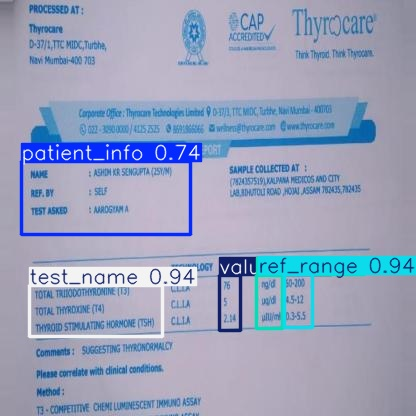

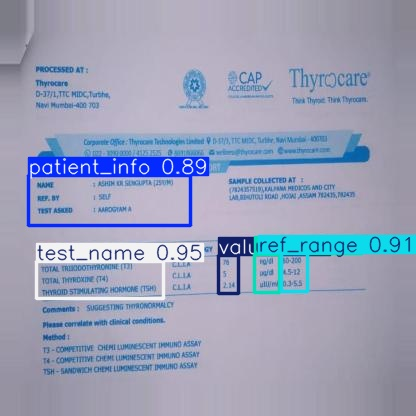

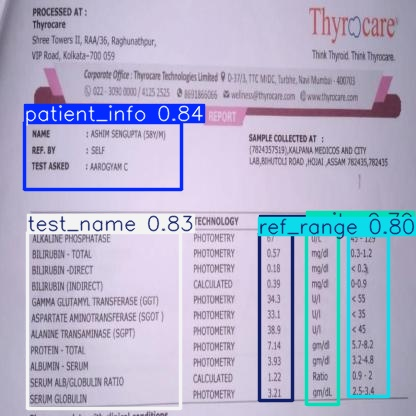

In [14]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob('/content/drive/MyDrive/Custom_OCR/results/validation_boxes/*.jpg'))[:3]:
    display(Image(f))

In [15]:
!apt-get -qq install tesseract-ocr > /dev/null

In [16]:
%%writefile /content/drive/MyDrive/Custom_OCR/Custom_OCR.py
import argparse, os, glob, csv
import cv2, pytesseract
from ultralytics import YOLO

MODEL = '/content/drive/MyDrive/Custom_OCR/models/yolov3_ocr/weights/best.pt'
OUT = '/content/drive/MyDrive/Custom_OCR/results'

def preprocess(crop):
    crop = cv2.resize(crop, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC)   # blow up 3x
    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)                               # grayscale
    blur = cv2.GaussianBlur(gray, (3, 3), 0)                                    # small blur
    thresh = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV | cv2.THRESH_OTSU)[1]  # Otsu: white text on black
    return cv2.bitwise_not(thresh)                                              # black text on white

def process(path, model, writer):
    img = cv2.imread(path)
    H, W = img.shape[:2]
    small = cv2.resize(img, (416, 416))          # same stretch used in training
    res = model.predict(small, imgsz=416, conf=0.25, verbose=False)[0]
    name = os.path.splitext(os.path.basename(path))[0]
    os.makedirs(f'{OUT}/crops', exist_ok=True)
    boxes = sorted(res.boxes, key=lambda b: (int(b.cls), float(b.xyxyn[0][1])))
    for i, b in enumerate(boxes):
        cls = model.names[int(b.cls)]
        x1, y1, x2, y2 = b.xyxyn[0].tolist()
        x1, x2 = int(x1 * W), int(x2 * W)
        y1, y2 = int(y1 * H), int(y2 * H)
        crop = img[max(y1-2, 0):y2+2, max(x1-2, 0):x2+2]
        if crop.size == 0:
            continue
        clean = preprocess(crop)
        cv2.imwrite(f'{OUT}/crops/{name}_{i}_{cls}.png', clean)
        text = pytesseract.image_to_string(clean, config='--psm 6').strip()
        text = ' | '.join(l.strip() for l in text.splitlines() if l.strip())
        writer.writerow([name, cls, x1, y1, x2, y2, round(float(b.conf), 2), text])

if __name__ == '__main__':
    ap = argparse.ArgumentParser()
    ap.add_argument('--image'); ap.add_argument('--folder')
    ap.add_argument('--out', default=f'{OUT}/ocr_output.csv')
    a = ap.parse_args()
    files = [a.image] if a.image else sorted(glob.glob(a.folder + '/*.jpg'))
    model = YOLO(MODEL)
    os.makedirs(OUT, exist_ok=True)
    with open(a.out, 'w', newline='') as f:
        w = csv.writer(f)
        w.writerow(['image', 'class', 'x1', 'y1', 'x2', 'y2', 'conf', 'text'])
        for p in files:
            process(p, model, w)
    print('Saved', a.out)

Writing /content/drive/MyDrive/Custom_OCR/Custom_OCR.py


In [18]:
!apt-get -qq install tesseract-ocr > /dev/null
!pip install -q pytesseract

In [19]:
!python /content/drive/MyDrive/Custom_OCR/Custom_OCR.py --image "/content/drive/MyDrive/Custom_OCR/datasets/images_raw/thyrocare_0_8491.jpg" --out /content/drive/MyDrive/Custom_OCR/results/one_image.csv
import pandas as pd
pd.set_option('display.max_colwidth', 80)
pd.read_csv('/content/drive/MyDrive/Custom_OCR/results/one_image.csv')[['class','conf','text']]

Saved /content/drive/MyDrive/Custom_OCR/results/one_image.csv


,class,conf,text
0,patient_info,0.81,WAMe 1 ASHIM SENGUPTA (58Y/M} | ReP. BY + SEU | TEST ASKED 3 AAROGYAM C
1,ref_range,0.97,Reference Range : | OBFICIENCY = <20 ng/mi | INSUFFICIENCY ; 20-< 20 ng/m! |...
2,ref_range,0.86,Reference Range: | Normal: 211-911 pgymi
3,test_name,0.66,25-08 VITAMIN D (TOTAL)
4,test_name,0.28,25-08 VITAMIN D (TOTAL)
5,test_name,0.28,Method: buuly Aun | VITAMIN B-12
6,test_name,0.31,VITAMIN B-12
7,units,0.53,ng/ml
8,units,0.56,pg/mi
9,value,0.44,21


In [20]:
%%writefile /content/drive/MyDrive/Custom_OCR/Custom_OCR.py
import argparse, os, glob, csv, re
import cv2, pytesseract
from ultralytics import YOLO

MODEL = '/content/drive/MyDrive/Custom_OCR/models/yolov3_ocr/weights/best.pt'
OUT = '/content/drive/MyDrive/Custom_OCR/results'
LET = 'abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789/%.^µ'
CFG = {
    'value': '--psm 6 -c tessedit_char_whitelist=0123456789.<>-',
    'units': f'--psm 6 -c tessedit_char_whitelist={LET}',
}

def preprocess(crop):
    crop = cv2.resize(crop, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC)
    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (3, 3), 0)
    thresh = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV | cv2.THRESH_OTSU)[1]
    return cv2.bitwise_not(thresh)

def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / union if union else 0

def dedupe(dets):
    keep = []
    for d in sorted(dets, key=lambda d: -d['conf']):
        if all(not (d['cls'] == k['cls'] and iou(d['box'], k['box']) > 0.4) for k in keep):
            keep.append(d)
    return keep

def fix(cls, t):
    if cls == 'units':
        t = t.replace('/mi', '/ml').replace('/m!', '/ml').replace('/ml!', '/ml')
    if cls == 'test_name':
        t = t.replace('25-08', '25-OH').replace('25-0H', '25-OH')
    return t

def process(path, model, writer):
    img = cv2.imread(path); H, W = img.shape[:2]
    res = model.predict(cv2.resize(img, (416, 416)), imgsz=416, conf=0.2, iou=0.5, verbose=False)[0]
    dets = [{'cls': model.names[int(b.cls)], 'conf': float(b.conf), 'box': b.xyxyn[0].tolist()} for b in res.boxes]
    dets = sorted(dedupe(dets), key=lambda d: (d['cls'], d['box'][1]))
    name = os.path.splitext(os.path.basename(path))[0]
    os.makedirs(f'{OUT}/crops', exist_ok=True)
    for i, d in enumerate(dets):
        x1, y1, x2, y2 = d['box']
        x1, x2, y1, y2 = int(x1*W), int(x2*W), int(y1*H), int(y2*H)
        crop = img[max(y1-4, 0):y2+4, max(x1-4, 0):x2+4]
        if crop.size == 0: continue
        clean = preprocess(crop)
        cv2.imwrite(f'{OUT}/crops/{name}_{i}_{d["cls"]}.png', clean)
        t = pytesseract.image_to_string(clean, config=CFG.get(d['cls'], '--psm 6')).strip()
        t = ' | '.join(l.strip() for l in t.splitlines() if l.strip())
        writer.writerow([name, d['cls'], x1, y1, x2, y2, round(d['conf'], 2), fix(d['cls'], t)])

if __name__ == '__main__':
    ap = argparse.ArgumentParser()
    ap.add_argument('--image'); ap.add_argument('--folder')
    ap.add_argument('--out', default=f'{OUT}/ocr_output.csv')
    a = ap.parse_args()
    files = [a.image] if a.image else sorted(glob.glob(a.folder + '/*.jpg'))
    model = YOLO(MODEL); os.makedirs(OUT, exist_ok=True)
    with open(a.out, 'w', newline='') as f:
        w = csv.writer(f); w.writerow(['image', 'class', 'x1', 'y1', 'x2', 'y2', 'conf', 'text'])
        for p in files: process(p, model, w)
    print('Saved', a.out)

Overwriting /content/drive/MyDrive/Custom_OCR/Custom_OCR.py


In [22]:
!python /content/drive/MyDrive/Custom_OCR/Custom_OCR.py --image "/content/drive/MyDrive/Custom_OCR/datasets/images_raw/thyrocare_0_8491.jpg" --out /content/drive/MyDrive/Custom_OCR/results/one_image.csv
import pandas as pd
pd.read_csv('/content/drive/MyDrive/Custom_OCR/results/one_image.csv')[['class','conf','text']]

Saved /content/drive/MyDrive/Custom_OCR/results/one_image.csv


,class,conf,text
0,patient_info,0.81,WAMe 1 ASHIM SENGUPTA (58Y/M} | ReP. BY + SEU | TEST ASKED 3 AAROGYAM C
1,ref_range,0.97,Reference Range : | DEFICIENCY: <20 ng/mi | INSUFFIGIENCY « 20-< 20 ng/mi | ...
2,ref_range,0.86,Reference Range: | Normal: 211-911 pgymi
3,test_name,0.66,25-OH VITAMIN D (TOTAL)
4,test_name,0.31,il ES ne | VITAMIN B-12 | ee
5,units,0.53,ng/ml
6,units,0.56,pg/ml
7,value,0.44,21
8,value,0.39,351


In [23]:
import glob, os, re, shutil
os.makedirs('/content/test_orig', exist_ok=True)
for f in glob.glob('/content/test_orig/*'): os.remove(f)
raw = '/content/drive/MyDrive/Custom_OCR/datasets/images_raw'
found = 0
for f in glob.glob('/content/yolo_data/images/test/*.jpg'):
    orig = re.sub(r'_(jpg|jpeg|png)\.rf\..*$', '.jpg', os.path.basename(f))
    if os.path.exists(f'{raw}/{orig}'):
        shutil.copy(f'{raw}/{orig}', '/content/test_orig/'); found += 1
print(found, 'originals found (should be 10)')

!python /content/drive/MyDrive/Custom_OCR/Custom_OCR.py --folder /content/test_orig --out /content/drive/MyDrive/Custom_OCR/results/ocr_output.csv

10 originals found (should be 10)
Saved /content/drive/MyDrive/Custom_OCR/results/ocr_output.csv


In [24]:
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/Custom_OCR/results/ocr_output.csv')
df['truth'] = df['text']      # pre-filled: you only fix the wrong ones
df[['image','class','conf','text','truth']].to_csv('/content/drive/MyDrive/Custom_OCR/results/ground_truth.csv', index=False)
print(df.image.nunique(), 'images,', len(df), 'rows')

10 images, 63 rows


In [25]:
import pandas as pd, difflib, re
base = '/content/drive/MyDrive/Custom_OCR/results'
pred = pd.read_csv(f'{base}/ocr_output.csv').fillna('')
gt = pd.read_csv(f'{base}/ground_truth_final.csv')

def norm(s): return re.sub(r'\s+', ' ', str(s).lower()).strip()

# join all predicted text for each image + field (top to bottom)
p = pred.groupby(['image', 'class'])['text'].apply(lambda x: ' | '.join(x)).reset_index()
m = gt.merge(p, on=['image', 'class'], how='left').fillna('')
m['similarity'] = [difflib.SequenceMatcher(None, norm(a), norm(b)).ratio() for a, b in zip(m['truth'], m['text'])]
m['exact'] = [norm(a) == norm(b) for a, b in zip(m['truth'], m['text'])]

print(m.groupby('class')[['similarity', 'exact']].mean().round(3))
print('Overall similarity:', round(m.similarity.mean(), 3))
m.to_csv(f'{base}/evaluation.csv', index=False)

              similarity  exact
class                          
patient_info       0.932    0.1
ref_range          0.925    0.5
test_name          0.895    0.2
units              0.808    0.1
value              0.950    0.8
Overall similarity: 0.902


In [26]:
import pandas as pd, difflib, re
base = '/content/drive/MyDrive/Custom_OCR/results'

UNITS = ['ng/ml','pg/ml','ng/dl','µg/dl','µIU/ml','mg/dl','U/l','gm/dl','Ratio']
NAMES = ['TOTAL TRIIODOTHYRONINE (T3)','TOTAL THYROXINE (T4)','THYROID STIMULATING HORMONE (TSH)',
         'ALKALINE PHOSPHATASE','BILIRUBIN - TOTAL','BILIRUBIN -DIRECT','BILIRUBIN (INDIRECT)',
         'GAMMA GLUTAMYL TRANSFERASE (GGT)','ASPARTATE AMINOTRANSFERASE (SGOT)','ALANINE TRANSAMINASE (SGPT)',
         'PROTEIN - TOTAL','ALBUMIN - SERUM','SERUM ALB/GLOBULIN RATIO','SERUM GLOBULIN',
         '25-OH VITAMIN D (TOTAL)','VITAMIN B-12']

def snap(line, vocab, cutoff):
    low = {v.lower(): v for v in vocab}
    m = difflib.get_close_matches(line.lower().strip(), list(low), n=1, cutoff=cutoff)
    return low[m[0]] if m else None

def clean_text(cls, text):
    lines = [l.strip() for l in str(text).split('|') if l.strip()]
    out = []
    for l in lines:
        if cls == 'units':
            out.append(snap(l, UNITS, 0.5) or l)
        elif cls == 'test_name':
            s = snap(l, NAMES, 0.6)
            if s: out.append(s)
            elif re.fullmatch(r'[A-Z0-9 ()/,.\-]{4,}', l): out.append(l)   # keep clean uppercase names
            # otherwise it is junk (e.g. "Method: buuly Aun") and is dropped
        else:
            out.append(l)
    if cls == 'test_name':                       # remove duplicate detections of the same test
        out = list(dict.fromkeys(out))
    return ' | '.join(out)

pred = pd.read_csv(f'{base}/ocr_output.csv').fillna('')
pred['text'] = [clean_text(c, t) for c, t in zip(pred['class'], pred['text'])]
pred.to_csv(f'{base}/ocr_output_clean.csv', index=False)

# re-score
gt = pd.read_csv(f'{base}/ground_truth_final.csv')
norm = lambda s: re.sub(r'\s+', ' ', str(s).lower()).strip()
p = pred.groupby(['image','class'])['text'].apply(lambda x: ' | '.join(x)).reset_index()
m = gt.merge(p, on=['image','class'], how='left').fillna('')
m['similarity'] = [difflib.SequenceMatcher(None, norm(a), norm(b)).ratio() for a, b in zip(m['truth'], m['text'])]
m['exact'] = [norm(a) == norm(b) for a, b in zip(m['truth'], m['text'])]
print(m.groupby('class')[['similarity','exact']].mean().round(3))
print('Overall similarity:', round(m.similarity.mean(), 3))
m.to_csv(f'{base}/evaluation_clean.csv', index=False)

              similarity  exact
class                          
patient_info       0.932    0.1
ref_range          0.925    0.5
test_name          0.980    0.8
units              0.888    0.3
value              0.950    0.8
Overall similarity: 0.935


In [27]:
%%writefile /content/drive/MyDrive/Custom_OCR/Custom_OCR.py
import argparse, os, glob, re, difflib
import cv2, pytesseract, pandas as pd
from ultralytics import YOLO

BASE = '/content/drive/MyDrive/Custom_OCR'
MODEL = f'{BASE}/models/yolov3_ocr/weights/best.pt'
UNITS = ['ng/ml','pg/ml','ng/dl','µg/dl','µIU/ml','mg/dl','U/l','gm/dl','Ratio']
NAMES = ['TOTAL TRIIODOTHYRONINE (T3)','TOTAL THYROXINE (T4)','THYROID STIMULATING HORMONE (TSH)',
         'ALKALINE PHOSPHATASE','BILIRUBIN - TOTAL','BILIRUBIN -DIRECT','BILIRUBIN (INDIRECT)',
         'GAMMA GLUTAMYL TRANSFERASE (GGT)','ASPARTATE AMINOTRANSFERASE (SGOT)','ALANINE TRANSAMINASE (SGPT)',
         'PROTEIN - TOTAL','ALBUMIN - SERUM','SERUM ALB/GLOBULIN RATIO','SERUM GLOBULIN',
         '25-OH VITAMIN D (TOTAL)','VITAMIN B-12']
LET = 'abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789/%.^µ'
CFG = {'value': '--psm 6 -c tessedit_char_whitelist=0123456789.<>-',
       'units': f'--psm 6 -c tessedit_char_whitelist={LET}'}

def preprocess(crop):
    crop = cv2.resize(crop, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC)
    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (3, 3), 0)
    thresh = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV | cv2.THRESH_OTSU)[1]
    return cv2.bitwise_not(thresh)

def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / union if union else 0

def dedupe(dets):
    keep = []
    for d in sorted(dets, key=lambda d: -d['conf']):
        if all(not (d['cls'] == k['cls'] and iou(d['box'], k['box']) > 0.4) for k in keep):
            keep.append(d)
    return keep

def snap(line, vocab, cutoff):
    low = {v.lower(): v for v in vocab}
    m = difflib.get_close_matches(line.lower().strip(), list(low), n=1, cutoff=cutoff)
    return low[m[0]] if m else None

def clean_lines(cls, text):
    out = []
    for l in [x.strip() for x in text.split('|') if x.strip()]:
        if cls == 'units':
            out.append(snap(l, UNITS, 0.5) or l)
        elif cls == 'test_name':
            s = snap(l, NAMES, 0.6)
            if s: out.append(s)
            elif re.fullmatch(r'[A-Z0-9 ()/,.\-]{4,}', l): out.append(l)
        else:
            out.append(l)
    return out

def ocr_image(path, model, crops_dir):
    img = cv2.imread(path); H, W = img.shape[:2]
    res = model.predict(cv2.resize(img, (416, 416)), imgsz=416, conf=0.2, iou=0.5, verbose=False)[0]
    dets = [{'cls': model.names[int(b.cls)], 'conf': float(b.conf), 'box': b.xyxyn[0].tolist()} for b in res.boxes]
    dets = sorted(dedupe(dets), key=lambda d: (d['cls'], d['box'][1]))
    name = os.path.splitext(os.path.basename(path))[0]
    raw, groups, seen = [], {}, set()
    for i, d in enumerate(dets):
        x1, y1, x2, y2 = d['box']
        x1, x2, y1, y2 = int(x1*W), int(x2*W), int(y1*H), int(y2*H)
        crop = img[max(y1-4, 0):y2+4, max(x1-4, 0):x2+4]
        if crop.size == 0: continue
        clean = preprocess(crop)
        cv2.imwrite(f'{crops_dir}/{name}_{i}_{d["cls"]}.png', clean)
        t = pytesseract.image_to_string(clean, config=CFG.get(d['cls'], '--psm 6'))
        lines = clean_lines(d['cls'], ' | '.join(l for l in t.splitlines() if l.strip()))
        if d['cls'] == 'test_name':                      # drop tests already read from another box
            lines = [l for l in lines if l not in seen]; seen.update(lines)
        groups.setdefault(d['cls'], []).append(lines)
        raw.append([name, d['cls'], x1, y1, x2, y2, round(d['conf'], 2), ' | '.join(lines)])
    return raw, build_report(name, groups)

def build_report(name, g):
    names = [l for ls in g.get('test_name', []) for l in ls]
    values = [l for ls in g.get('value', []) for l in ls]
    units = [l for ls in g.get('units', []) for l in ls]
    refs = g.get('ref_range', [])
    n = max(len(names), len(values), len(units), 1)
    flat = [l for r in refs for l in r]
    if len(refs) == n:   ref_list = [' '.join(r) for r in refs]
    elif len(flat) == n: ref_list = flat
    else:                ref_list = [' '.join(flat)] + [''] * (n - 1)
    pad = lambda L: (L + [''] * n)[:n]
    patient = ' '.join(l for ls in g.get('patient_info', [])[:1] for l in ls)
    return [[name, patient, a, b, c, d] for a, b, c, d in zip(pad(names), pad(values), pad(units), pad(ref_list))]

if __name__ == '__main__':
    ap = argparse.ArgumentParser()
    ap.add_argument('--image'); ap.add_argument('--folder')
    ap.add_argument('--out', default=f'{BASE}/results')
    a = ap.parse_args()
    files = [a.image] if a.image else sorted(glob.glob(a.folder + '/*.jpg'))
    os.makedirs(f'{a.out}/crops', exist_ok=True)
    model = YOLO(MODEL)
    raw, report = [], []
    for p in files:
        r1, r2 = ocr_image(p, model, f'{a.out}/crops'); raw += r1; report += r2
    pd.DataFrame(raw, columns=['image','class','x1','y1','x2','y2','conf','text']).to_csv(f'{a.out}/ocr_output.csv', index=False)
    rep = pd.DataFrame(report, columns=['image','patient_info','test_name','value','units','ref_range'])
    rep.to_csv(f'{a.out}/report.csv', index=False); rep.to_excel(f'{a.out}/report.xlsx', index=False)
    print('Saved ocr_output.csv, report.csv, report.xlsx in', a.out)

Overwriting /content/drive/MyDrive/Custom_OCR/Custom_OCR.py


In [28]:
!pip install -q openpyxl
!python /content/drive/MyDrive/Custom_OCR/Custom_OCR.py --image "/content/drive/MyDrive/Custom_OCR/datasets/images_raw/thyrocare_0_8491.jpg" --out /content/drive/MyDrive/Custom_OCR/results/demo
import pandas as pd
pd.read_csv('/content/drive/MyDrive/Custom_OCR/results/demo/report.csv')

Saved ocr_output.csv, report.csv, report.xlsx in /content/drive/MyDrive/Custom_OCR/results/demo


,image,patient_info,test_name,value,units,ref_range
0,thyrocare_0_8491,WAMe 1 ASHIM SENGUPTA (58Y/M} ReP. BY + SEU TEST ASKED 3 AAROGYAM C,25-OH VITAMIN D (TOTAL),21,ng/ml,Reference Range : DEFICIENCY: <20 ng/mi INSUFFIGIENCY « 20-< 20 ng/mi SUFFIC...
1,thyrocare_0_8491,WAMe 1 ASHIM SENGUPTA (58Y/M} ReP. BY + SEU TEST ASKED 3 AAROGYAM C,VITAMIN B-12,351,pg/ml,Reference Range: Normal: 211-911 pgymi


In [29]:
!python /content/drive/MyDrive/Custom_OCR/Custom_OCR.py --folder /content/test_orig --out /content/drive/MyDrive/Custom_OCR/results

Saved ocr_output.csv, report.csv, report.xlsx in /content/drive/MyDrive/Custom_OCR/results


In [30]:
from ultralytics import YOLO
import pandas as pd, difflib, re, os, glob
base = '/content/drive/MyDrive/Custom_OCR'

# 1) Detection metrics on the TEST set
model = YOLO(f'{base}/models/yolov3_ocr/weights/best.pt')
m = model.val(data='/content/yolo_data/data.yaml', split='test', imgsz=416, device=0, verbose=False)
print('DETECTION (test set) -> precision %.3f | recall %.3f | mAP50 %.3f | mAP50-95 %.3f' %
      (m.box.mp, m.box.mr, m.box.map50, m.box.map))
for idx, ap in zip(m.box.ap_class_index, m.box.ap50):
    print('   ', model.names[int(idx)], 'mAP50 = %.3f' % ap)

# 2) Final OCR accuracy (output of Custom_OCR.py vs ground truth)
pred = pd.read_csv(f'{base}/results/ocr_output.csv').fillna('')
gt = pd.read_csv(f'{base}/results/ground_truth_final.csv')
norm = lambda s: re.sub(r'\s+', ' ', str(s).lower()).strip()
p = pred.groupby(['image','class'])['text'].apply(lambda x: ' | '.join(x)).reset_index()
e = gt.merge(p, on=['image','class'], how='left').fillna('')
e['similarity'] = [difflib.SequenceMatcher(None, norm(a), norm(b)).ratio() for a, b in zip(e['truth'], e['text'])]
print('\nOCR similarity by field:'); print(e.groupby('class')['similarity'].mean().round(3))
print('Overall OCR similarity:', round(e.similarity.mean(), 3))

# 3) What is saved in Drive
for d in ['models/yolov3_ocr/weights', 'results']:
    print('\n', d, '->', sorted(os.listdir(f'{base}/{d}'))[:12])

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv3 summary (fused): 96 layers, 103,668,095 parameters, 0 gradients, 282.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 84.0±129.6 MB/s, size: 20.2 KB)
val: Scanning /content/yolo_data/labels/test... 10 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10/10 465.1it/s 0.0s
val: New cache created: /content/yolo_data/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.8it/s 0.6s
                   all         10         62      0.968      0.956      0.975      0.612
Speed: 0.2ms preprocess, 35.3ms inference, 0.0ms loss, 3.0ms postprocess per image
Results saved to /content/runs/detect/val-2
DETECTION (test set) -> precision 0.968 | recall 0.956 | mAP50 0.975 | mAP50-95 0.612
    patient_info mAP50 = 0.995
    ref_range mAP50 = 0.995
    test_name mAP50 = 0.966
    units mAP50 = 0.995
    value mAP50 = 0.925

O